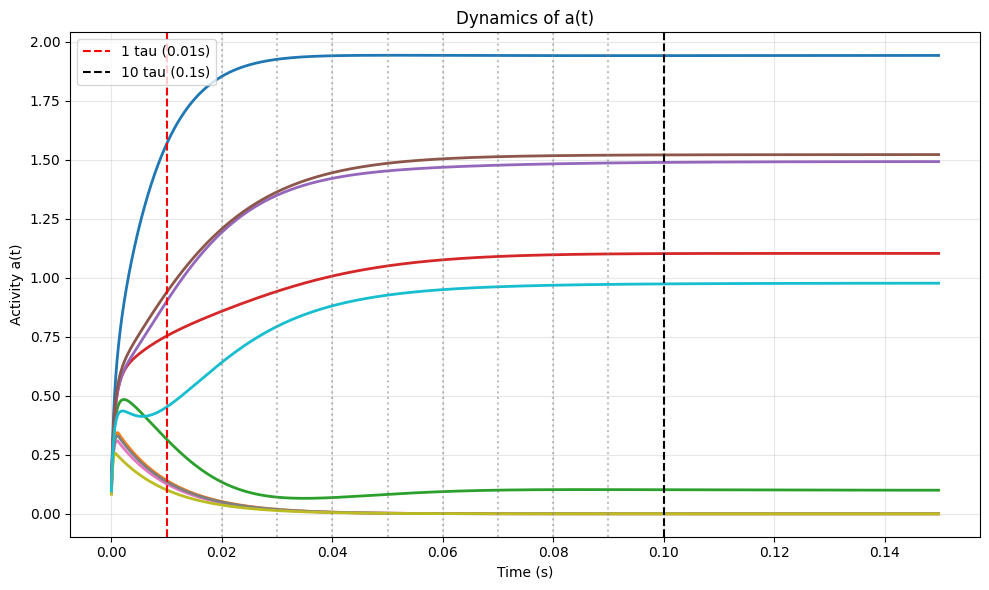

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETRI (Zoom sul Transiente)
# ==========================================
N_S = 100
N_R = 500
tau = 0.01

# PRECISIONE ALTA (dt piccolo) per vedere le oscillazioni vere
dt = 0.0001       # 0.1 ms
# DURATION BREVE: Simuliamo solo 0.2 secondi (20*tau)
duration = 0.15    
steps = int(duration / dt)

# Parametri Stabili (g < 1) ma con dinamica ricca
g_rec_factor = 0.8   # Aumentato leggermente a 0.8 per avere più "rimbalzi"
g_input_factor = 2.0

sigma_rec = g_rec_factor / np.sqrt(N_R)
sigma_in = g_input_factor / np.sqrt(N_S)
mu_rec = -1.0 / np.sqrt(N_R)
mu_in = 2.0 / np.sqrt(N_S)

dtype = np.float32

# ==========================================
# 2. GENERAZIONE E SIMULAZIONE
# ==========================================

J_rec = np.random.normal(loc=mu_rec, scale=sigma_rec, size=(N_R, N_R)).astype(dtype)
J_in = np.random.normal(loc=mu_in, scale=sigma_in, size=(N_R, N_S)).astype(dtype)
pattern_S = np.random.choice([0, 1], size=N_S, p=[0.5, 0.5]).astype(dtype)
I_drive = np.dot(J_in, pattern_S)

a_R = np.zeros(N_R, dtype=dtype)

# Salviamo 10 neuroni per vederne i dettagli
history_zoom = np.zeros((steps, 10))

for t in range(steps):
    total_field = np.dot(J_rec, a_R) + I_drive
    d_a = (-a_R + np.maximum(0, total_field)) / tau
    a_R += d_a * dt
    history_zoom[t, :] = a_R[:10]

# ==========================================
# 3. GRAFICO ZOOMATO (Transiente)
# ==========================================
time_axis = np.arange(steps) * dt

plt.figure(figsize=(10, 6))
plt.plot(time_axis, history_zoom, linewidth=2)

plt.title(f"Dynamics of a(t)", fontsize=14)
plt.xlabel("Time (s)", fontsize=12, weight='bold')
plt.ylabel("Activity a(t)", fontsize=12, weight='bold')
plt.grid(True, alpha=0.3, which='both')

# Segna i multipli di tau per capire la scala temporale
for i in range(1, 11):
    plt.axvline(i*tau, color='gray', linestyle=':', alpha=0.5)

plt.axvline(tau, color='r', linestyle='--', label='1 tau (0.01s)')
plt.axvline(10*tau, color='k', linestyle='--', label='10 tau (0.1s)')

plt.legend()
plt.tight_layout()
plt.show()

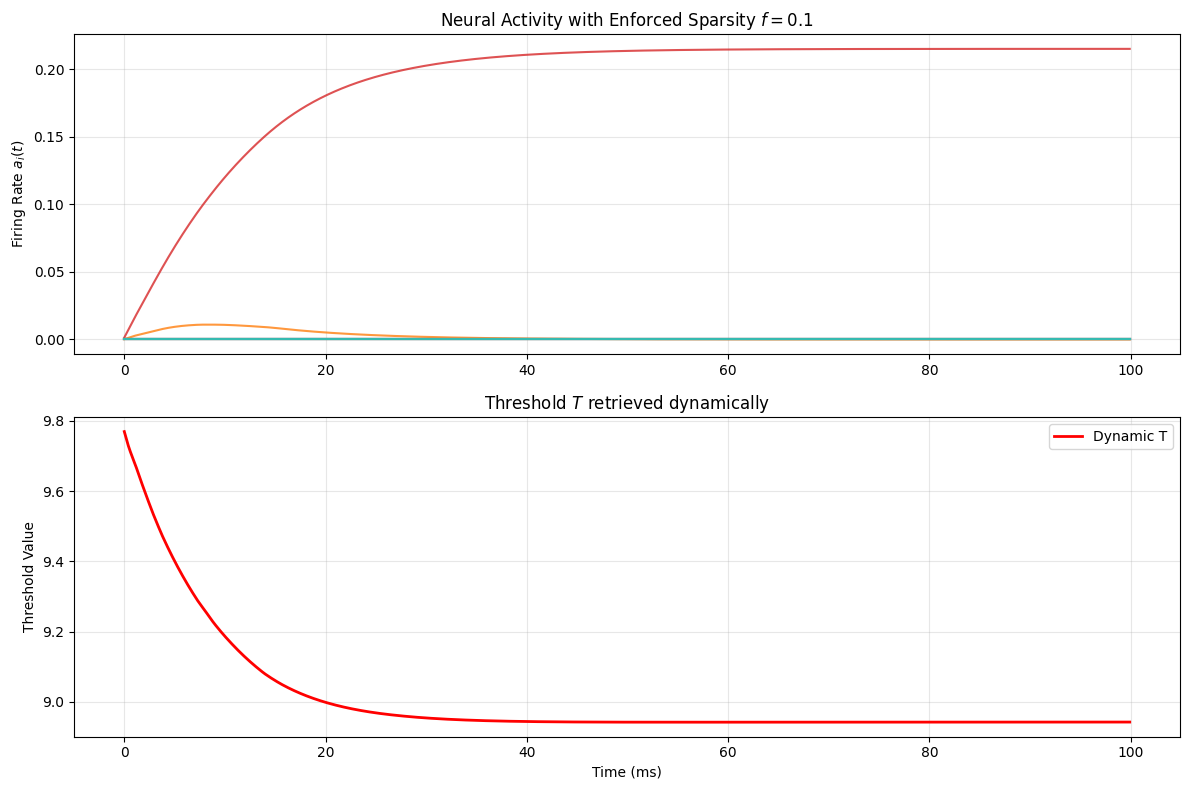

Target Sparsity: 0.1
Final Measured Sparsity: 0.11


In [108]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup Parameters
np.random.seed(42)
N_S = 100    # Input layer size
N_R = 500    # Recurrent layer size
dt = 0.1     # Time step (ms)
tau = 10.0   # Time constant (ms)
T_max = 100  # Duration (ms)
time_vec = np.arange(0, T_max, dt)

# --- SPARSITY TARGET ---
# We want exactly 10% of neurons to be active
target_sparsity = 0.10  

# 2. Define Weights
mu_ext, sigma_ext = 1.0, 0.5    
mu_rec, sigma_rec = -1.5, 0.5   # Inhibitory Recurrent weights

W_ext = np.random.normal(mu_ext, sigma_ext, (N_R, N_S)) / np.sqrt(N_S)
W_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)) / np.sqrt(N_R)

# 3. Input & Initialization
a_S = np.random.rand(N_S) * 2.0  
I_ext = np.dot(W_ext, a_S)       
a_R = np.zeros(N_R)
activity_history = []
threshold_history = []  # To track how T changes

for t in time_vec:
    # Calculate Recurrent Input
    I_rec = np.dot(W_rec, a_R)
    
    # Total Input Current H (before thresholding)
    H = I_ext + I_rec
    
    # --- RETRIEVE T FROM SPARSITY ---
    # We want top 10% of H to be > T.
    # Therefore, T is the (1 - target_sparsity) percentile of H.
    # e.g., for 10% sparsity, T is the 90th percentile.
    T_dynamic = np.percentile(H, (1.0 - target_sparsity) * 100)
    
    # Apply Activation Function
    # phi(x) = max(0, H - T)
    transfer_func = np.maximum(0, H - T_dynamic)
    
    # Differential Equation Update
    da_dt = (-a_R + transfer_func) / tau
    a_R += da_dt * dt
    
    # Store data
    activity_history.append(a_R.copy())
    threshold_history.append(T_dynamic)

activity_history = np.array(activity_history)

# 4. Visualization
plt.figure(figsize=(12, 8))

# Subplot 1: Neural Activity
plt.subplot(2, 1, 1)
neurons_to_plot = np.random.choice(N_R, 10, replace=False)
plt.plot(time_vec, activity_history[:, neurons_to_plot], alpha=0.8)
plt.title(f"Neural Activity with Enforced Sparsity $f={target_sparsity}$")
plt.ylabel("Firing Rate $a_i(t)$")
plt.grid(True, alpha=0.3)

# Subplot 2: Dynamic Threshold T
plt.subplot(2, 1, 2)
plt.plot(time_vec, threshold_history, color='red', linewidth=2, label="Dynamic T")
plt.title("Threshold $T$ retrieved dynamically")
plt.xlabel("Time (ms)")
plt.ylabel("Threshold Value")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Verification
final_active_fraction = np.mean(activity_history[-1] > 0)
print(f"Target Sparsity: {target_sparsity}")
print(f"Final Measured Sparsity: {final_active_fraction:.2f}")

# Perceptron classification

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. FUNZIONI DI SUPPORTO (Dinamica & Dati)
# ==========================================

def generate_central_patterns(P, N):
    """Genera P pattern binari random di dimensione N"""
    return np.random.choice([0, 1], size=(P, N), p=[0.5, 0.5])

def generate_variations(patterns, labels, V, flip_prob):
    """
    Genera varianti rumorose dei pattern (flip dei bit).
    Ritorna: (patterns_rumorosi, labels_espanse, indici_originali)
    """
    P, N = patterns.shape
    noisy_patterns = []
    expanded_labels = []
    
    for i in range(P):
        pat = patterns[i]
        lab = labels[i]
        for _ in range(V):
            # Crea rumore flippando bit con probabilità flip_prob
            noise_mask = np.random.rand(N) < flip_prob
            new_pat = np.logical_xor(pat, noise_mask).astype(int)
            noisy_patterns.append(new_pat)
            expanded_labels.append(lab)
            
    return np.array(noisy_patterns), np.array(expanded_labels), None

def run_reservoir_dynamics(inputs, J_in, J_rec, tau=0.01, dt=0.001, steps=200):
    """
    Simula la rete ricorrente fino allo stato stazionario.
    inputs: (Batch_Size, N_S)
    Output: (Batch_Size, N_R) - Stato stazionario
    """
    # 1. Calcolo Input Drive costante (Statico)
    # I_drive ha shape (Batch, N_R)
    I_drive = inputs @ J_in.T
    
    # 2. Inizializzazione stato (Batch, N_R)
    a = np.zeros_like(I_drive, dtype=np.float32)
    
    # 3. Loop Temporale (Eulero)
    # Usiamo steps ridotti ma sufficienti perché la rete è stabile
    for _ in range(steps):
        # Calcolo campo ricorrente per tutto il batch
        rec_input = a @ J_rec.T
        
        total_input = I_drive + rec_input
        
        # Dinamica: tau * da/dt = -a + ReLU(Input)
        da = (-a + np.maximum(0, total_input)) / tau
        a += da * dt
        
    return a

def apply_sparsity_threshold(activity, f):
    """
    Applica una soglia k-WTA per ottenere esattamente sparsità f.
    activity: (Batch, N_R) valori continui
    f: target sparsity (0.0 - 1.0)
    Returns: pattern binari (0/1)
    """
    Batch, N = activity.shape
    # Numero di neuroni da tenere accesi
    k = int(f * N)
    if k == 0: k = 1 # Evita errori
    
    # Trova la soglia per ogni pattern nel batch
    # np.partition mette i k elementi più grandi alla fine
    # Prendiamo il valore del k-esimo elemento più grande come soglia
    thresholds = np.partition(activity, -k, axis=1)[:, -k]
    thresholds = thresholds.reshape(-1, 1)
    
    # Binarizzazione
    binary_output = (activity >= thresholds).astype(int)
    return binary_output

# ==========================================
# 2. TRAINING DEL PERCEPTRON
# ==========================================

def train_perceptron_reservoir(
    central_patterns, labels, 
    J_in, J_rec, 
    f, 
    deltaS_learn=0.1, eta=0.001, 
    max_epochs=50, patience=3
):
    P, N_S = central_patterns.shape
    N_R = J_rec.shape[0]
    flip_prob = deltaS_learn / 2

    # Inizializzazione pesi Perceptron
    W = np.random.normal(0, 1 / np.sqrt(N_R), size=N_R)
    
    # Ottimizzazione: Per velocizzare, pre-calcoliamo lo stato stazionario dei pattern centrali
    # Nota: Nel codice originale si aggiungeva rumore a ogni epoca. 
    # Qui lo facciamo, ma dobbiamo simulare la dinamica ogni volta (lento).
    # Per questo esempio, simuliamo un batch di training rumoroso all'inizio di ogni epoca o blocco.
    
    block_size = 10
    block_errors = []
    
    # Pre-calcolo soglia di sparsità usando i pattern centrali puliti
    # Questo serve a definire il "working point" della rete per questo f
    clean_activity = run_reservoir_dynamics(central_patterns, J_in, J_rec)
    
    # Calcoliamo una soglia GLOBALE media o locale? 
    # Usiamo la logica locale (k-WTA) pattern per pattern per garantire f esatto.
    
    for epoch in range(max_epochs):
        # 1. Genera batch rumoroso per questa epoca
        # Usiamo V=1 variazione per pattern per l'epoca corrente
        noisy_patterns, epoch_labels, _ = generate_variations(central_patterns, labels, V=1, flip_prob=flip_prob)
        
        # 2. Proietta nel Reservoir (Dinamica)
        analog_states = run_reservoir_dynamics(noisy_patterns, J_in, J_rec)
        
        # 3. Applica Sparsità
        sparse_states = apply_sparsity_threshold(analog_states, f)
        
        # 4. Centra i dati (tecnica standard per velocizzare perceptron: x - f)
        states_centered = sparse_states - f
        
        # 5. Update Pesi (Vettorializzato o loop)
        # Loop classico per simulare apprendimento online
        errors_in_epoch = 0
        for i in range(len(epoch_labels)):
            x = sparse_states[i]      # 0/1 vector
            x_c = states_centered[i]  # centered vector
            y = epoch_labels[i]
            
            # Predizione lineare
            if y * np.dot(W, x_c) <= 0:
                # Errore: update
                W += eta * y * x_c # Regola perceptron usando input centrato o non? Spesso si usa x non centrato per update
                errors_in_epoch += 1
        
        # Check convergenza
        err_rate = errors_in_epoch / len(epoch_labels)
        block_errors.append(err_rate)
        
        if epoch % 10 == 0:
            print(f"   Epoch {epoch}: Train Error {err_rate:.4f}")

        # Early stopping semplice
        if len(block_errors) > patience and np.mean(block_errors[-patience:]) < 1e-3:
            break
            
    return W

def test_perceptron(W, central_patterns, labels, J_in, J_rec, f, deltaS_test=0.2):
    # Genera test set rumoroso
    noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V=5, flip_prob=deltaS_test/2)
    
    # Reservoir Dynamics
    analog_states = run_reservoir_dynamics(noisy_test, J_in, J_rec)
    
    # Sparsity
    sparse_states = apply_sparsity_threshold(analog_states, f)
    
    # Predict
    # x_centered = x - f
    preds = np.sign((sparse_states - f) @ W)
    preds[preds == 0] = 1 # Gestione casi limite
    
    error = 1 - np.mean(preds == test_labels)
    return error

In [40]:
# Parametri
P = 500             # Numero pattern (ridotto per velocità demo, puoi rimettere 1000)
N_S = 500          # Input size
N_R = 5000         # Reservoir size (Grande!)
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.01          # Learning rate un po' più alto per convergere prima
f_values = np.linspace(0.01, 0.2, 15) # Sparsity da testare

# Parametri Stabilità Reservoir (Dal nostro fix precedente)
g_rec_factor = 0.7  # Stabile
g_input_factor = 2.0
mu_rec = -1.0 / np.sqrt(N_R)
sigma_rec = g_rec_factor / np.sqrt(N_R)
# Input matrix
mu_in = 2.0 / np.sqrt(N_S)
sigma_in = g_input_factor / np.sqrt(N_S)

n_iterations = 1
n_runs = 5  # Media su 3 run per ogni f

all_results_mean = []
all_results_std = []

print(f"Avvio simulazione: P={P}, N_R={N_R}, g={g_rec_factor} (Stable)")

for f in f_values:
    print(f"\n--- Testing Sparsity f = {f:.3f} ---")
    run_errors = []
    
    for r in range(n_runs):
        # 1. Generazione Dati
        labels = np.random.choice([-1, 1], size=P)
        central_patterns = generate_central_patterns(P, N_S)
        
        # 2. Generazione Matrici Reservoir (fisse per questo run)
        # Usiamo float32 per memoria
        J_in = np.random.normal(mu_in, sigma_in, (N_R, N_S)).astype(np.float32)
        J_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)).astype(np.float32)
        
        # 3. Training
        W = train_perceptron_reservoir(
            central_patterns, labels, J_in, J_rec, f, 
            deltaS_learn=deltaS_learn, eta=eta
        )
        
        # 4. Testing
        err = test_perceptron(W, central_patterns, labels, J_in, J_rec, f, deltaS_test=deltaS_test)
        run_errors.append(err)
        print(f"   Run {r+1}: Error = {err:.4f}")
        
    all_results_mean.append(np.mean(run_errors))
    all_results_std.append(np.std(run_errors))

# ==========================================
# 4. PLOT FINALE
# ==========================================
plt.figure(figsize=(8, 6))
plt.errorbar(
    f_values, all_results_mean, yerr=all_results_std,
    marker='o', lw=2, capsize=4, color='teal', label='Recurrent Reservoir'
)

plt.xlabel("Perceptron error vs  sparsity $f_R$", fontsize=14)
plt.ylabel(f"Classification Error", fontsize=12, fontweight='bold')
plt.title(f"Perceptron Capacity con Dinamica Ricorrente\n($N_R={N_R}$, $g={g_rec_factor}$)")
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

Avvio simulazione: P=500, N_R=5000, g=0.7 (Stable)

--- Testing Sparsity f = 0.010 ---
   Epoch 0: Train Error 0.4600
   Epoch 10: Train Error 0.2800
   Epoch 20: Train Error 0.2000
   Epoch 30: Train Error 0.1660
   Epoch 40: Train Error 0.1980
   Run 1: Error = 0.2448
   Epoch 0: Train Error 0.5060
   Epoch 10: Train Error 0.2700
   Epoch 20: Train Error 0.1880
   Epoch 30: Train Error 0.1760
   Epoch 40: Train Error 0.1620
   Run 2: Error = 0.2540
   Epoch 0: Train Error 0.5200
   Epoch 10: Train Error 0.2800
   Epoch 20: Train Error 0.2060
   Epoch 30: Train Error 0.2060
   Epoch 40: Train Error 0.1900
   Run 3: Error = 0.2476
   Epoch 0: Train Error 0.4620
   Epoch 10: Train Error 0.2580
   Epoch 20: Train Error 0.1980
   Epoch 30: Train Error 0.1800
   Epoch 40: Train Error 0.1680
   Run 4: Error = 0.2440
   Epoch 0: Train Error 0.5220
   Epoch 10: Train Error 0.2560
   Epoch 20: Train Error 0.2160
   Epoch 30: Train Error 0.1920
   Epoch 40: Train Error 0.1800
   Run 5: Error = 

KeyboardInterrupt: 